In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

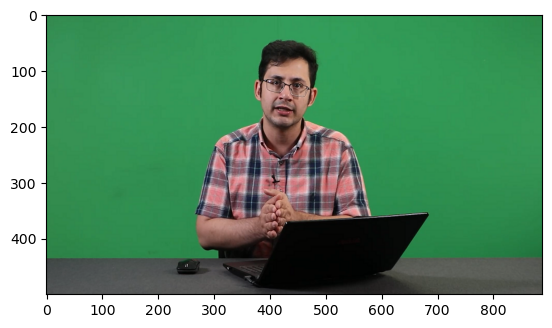

In [2]:
image = cv2.imread("/mnt/e/Image processing and computer vision using OpenCV/class.vision-master/images/green-sccreen.png")
plt.imshow(image[..., ::-1])

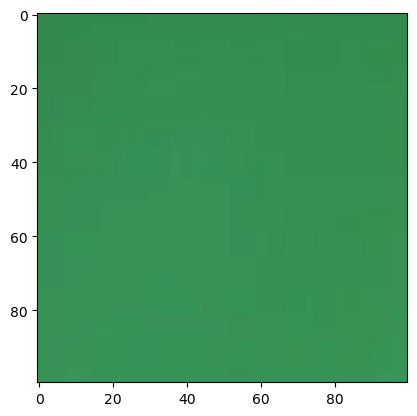

In [5]:
patch = image[:100, :100]
plt.imshow(patch[..., ::-1])

In [6]:
patch_hsv = cv2.cvtColor(patch, cv2.COLOR_BGR2HSV)
print(patch_hsv.shape)

(100, 100, 3)


In [11]:
h_mean, s_mean, v_mean = np.mean(patch_hsv, axis=(0, 1))
print(h_mean, s_mean, v_mean)

70.3095 161.9527 144.0222


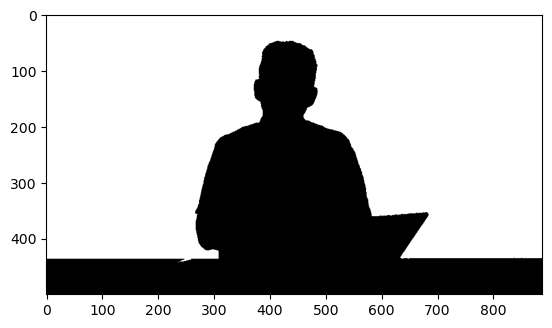

In [12]:
hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

lower = np.array([60, 50, 50])
upper = np.array([80, 255, 255])

mask_green = cv2.inRange(hsv_image, lower, upper)
plt.imshow(mask_green, cmap='gray')

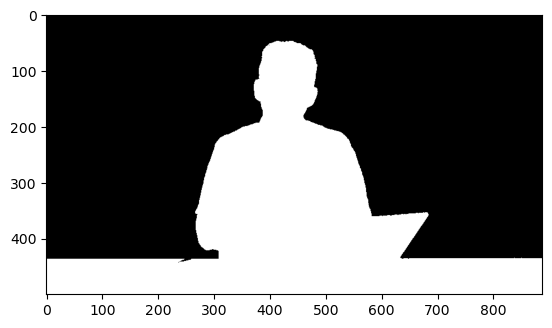

In [13]:
mask_object = cv2.bitwise_not(mask_green)
plt.imshow(mask_object, cmap='gray')

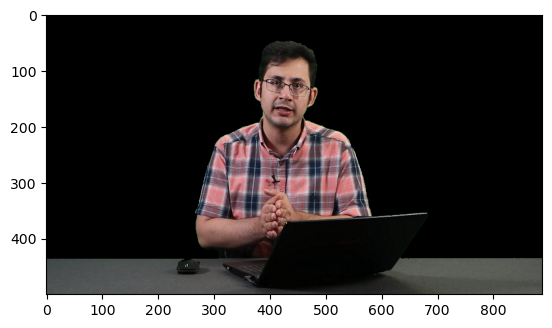

In [14]:
removed_bg = cv2.bitwise_and(image, image, mask=mask_object)
plt.imshow(removed_bg[..., ::-1])

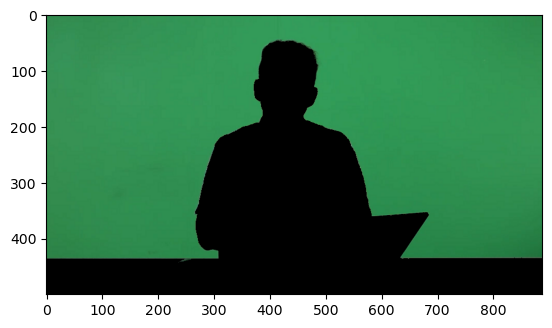

In [15]:
removed_ob = cv2.bitwise_and(image, image, mask=mask_green)
plt.imshow(removed_ob[..., ::-1])

In [27]:
h, w, _ = image.shape

ballon = cv2.imread("/mnt/e/Image processing and computer vision using OpenCV/class.vision-master/images/balloon.png")
print(ballon.shape)

ballon_resized = cv2.resize(ballon, (w, h))
print(ballon_resized.shape)

(278, 372, 3)
(500, 888, 3)


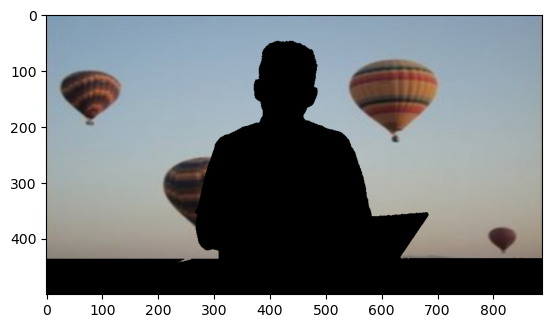

In [28]:
removed_ob_in_ballon = cv2.bitwise_and(ballon_resized, ballon_resized, mask=mask_green)
plt.imshow(removed_ob_in_ballon[..., ::-1])

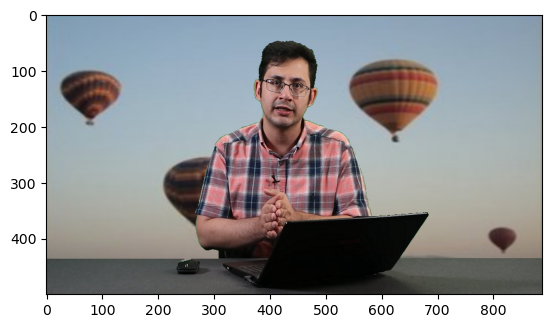

In [29]:
new_image = removed_ob_in_ballon + removed_bg
plt.imshow(new_image[..., ::-1])

# Another aproach

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [13]:
cap = cv2.VideoCapture("/mnt/e/Image processing and computer vision using OpenCV/class.vision-master/videos/akhavan-green-bg.mp4")
image = cv2.imread("/mnt/e/Image processing and computer vision using OpenCV/class.vision-master/images/balloon.png")

lower = np.array([40, 50, 50])
upper = np.array([90, 255, 255])

while True:
    retval, frame = cap.read()
    if not retval:
        break

    h, w, _ = frame.shape
    image_resized = cv2.resize(image, (w, h))

    hsv_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

    mask_green = cv2.inRange(hsv_frame, lower, upper)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask_green  =cv2.dilate(mask_green, kernel)
    mask_object = cv2.bitwise_not(mask_green)

    image_resized = cv2.bitwise_and(image_resized, image_resized, mask=mask_green)

    obj_image = cv2.bitwise_and(frame, frame, mask=mask_object)

    out = cv2.bitwise_or(image_resized, obj_image)

    
    cv2.imshow("Video", out)

    if cv2.waitKey(25) & 0XFF == 27:
        break

cap.release()
cv2.destroyAllWindows()


# LAB

In [14]:
cap = cv2.VideoCapture(
    "/mnt/e/Image processing and computer vision using OpenCV/class.vision-master/videos/akhavan-green-bg.mp4"
)

image = cv2.imread(
    "/mnt/e/Image processing and computer vision using OpenCV/class.vision-master/images/balloon.png"
)

while True:
    ret, frame = cap.read()

    if not ret:
        break

    h, w, _ = frame.shape

    # Resize background
    background = cv2.resize(image, (w, h))

    # Convert BGR to LAB
    lab = cv2.cvtColor(frame, cv2.COLOR_BGR2LAB)

    # Extract A channel
    a_channel = lab[:, :, 1]

    # Otsu thresholding
    _, th = cv2.threshold(
        a_channel,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Invert mask
    mask_green = cv2.bitwise_not(th)

    # Keep object from original frame
    removed_bg = cv2.bitwise_and(
        frame,
        frame,
        mask=th
    )

    # Keep background where the green background was
    background = cv2.bitwise_and(
        background,
        background,
        mask=mask_green
    )

    # Combine object and new background
    final = cv2.add(
        removed_bg,
        background
    )

    cv2.imshow("Video", final)

    if cv2.waitKey(25) & 0xFF == 27:
        break

cap.release()
cv2.destroyAllWindows()